# Phase 2: Data Acquisition, Understanding and Preparation

In [1]:
import os, re, json, hashlib, random, pathlib, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter, ImageEnhance

SEED = 42
random.seed(SEED); np.random.seed(SEED)

for d in ["data/processed", "splits", "figures", "results"]:
    pathlib.Path(d).mkdir(parents=True, exist_ok=True)

RESAMPLE = getattr(Image, "Resampling", Image)
TRANSPOSE = getattr(Image, "Transpose", Image)
print("Python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__)

Python 3.13.16 | numpy 2.1.3 | pandas 2.2.3


## 1. Data acquisition
The Kaggle dataset contains several files. We only use the folder of 5,000 full-colour 150×150 tiles, organised in class folders `01_TUMOR` ... `08_EMPTY`. The CSV versions (`hmnist_*`) are **not** used.

In [2]:
DATASET = "kmader/colorectal-histology-mnist"

def find_tiles_root(base):
    # Return the folder that directly contains the class folders 01_..., 08_...
    base = pathlib.Path(base)
    if not base.exists():
        return None
    parents = [p.parent for p in base.rglob("*") if p.is_dir() and re.match(r"^0[1-8]_", p.name)]
    return max(set(parents), key=parents.count) if parents else None

TILES_ROOT = None
for cand in [os.environ.get("KATHER_DATA"), "data/raw", "/kaggle/input/colorectal-histology-mnist"]:
    if cand:
        TILES_ROOT = find_tiles_root(cand)
    if TILES_ROOT:
        break

if TILES_ROOT is None:
    try:
        import kagglehub
        TILES_ROOT = find_tiles_root(kagglehub.dataset_download(DATASET))
    except Exception as e:
        print("kagglehub download failed:", e)

if TILES_ROOT is None:
    raise FileNotFoundError
print("Tiles folder:", TILES_ROOT)

100%|██████████| 1.90G/1.90G [00:18<00:00, 109MB/s] 

Extracting files...


Tiles folder: /root/.cache/kagglehub/datasets/kmader/colorectal-histology-mnist/versions/2/Kather_texture_2016_image_tiles_5000/Kather_texture_2016_image_tiles_5000


## 2. Image index and label verification
Labels come from the folder number (1–8). The class names follow the original dataset's folder order.

In [3]:
CLASS_NAMES = {1: "Tumour epithelium", 2: "Simple stroma", 3: "Complex stroma", 4: "Immune cells (lympho)",
               5: "Debris and mucus", 6: "Normal mucosal glands", 7: "Adipose tissue", 8: "Background (empty)"}
EXPECTED_FOLDERS = {1: "TUMOR", 2: "STROMA", 3: "COMPLEX", 4: "LYMPHO", 5: "DEBRIS", 6: "MUCOSA", 7: "ADIPOSE", 8: "EMPTY"}
IMG_EXT = {".tif", ".tiff", ".png", ".jpg", ".jpeg"}

rows = []
for d in sorted(pathlib.Path(TILES_ROOT).iterdir()):
    m = re.match(r"^(\d{2})_(.+)$", d.name)
    if d.is_dir() and m:
        for f in sorted(d.iterdir()):
            if f.suffix.lower() in IMG_EXT:
                rows.append((str(f), f"{d.name}/{f.name}", int(m.group(1)), m.group(2)))
df = pd.DataFrame(rows, columns=["path", "rel_path", "label", "folder_suffix"])
df["class_name"] = df["label"].map(CLASS_NAMES)

print("Total images:", len(df))
print("Labels found:", sorted(int(v) for v in df.label.unique()))
print(df.groupby(["label", "folder_suffix"]).size().rename("images").reset_index().to_string(index=False))
for lab, suffix in df.groupby("label").folder_suffix.first().items():
    if suffix != EXPECTED_FOLDERS.get(lab):
        warnings.warn(f"Label {lab}: folder suffix '{suffix}' differs from expected '{EXPECTED_FOLDERS.get(lab)}'. Check the class-name mapping.")

Total images: 5000
Labels found: [1, 2, 3, 4, 5, 6, 7, 8]
 label folder_suffix  images
     1         TUMOR     625
     2        STROMA     625
     3       COMPLEX     625
     4        LYMPHO     625
     5        DEBRIS     625
     6        MUCOSA     625
     7       ADIPOSE     625
     8         EMPTY     625


## 3. Cleaning and integrity checks
Checks: files open correctly, all images are 150×150 RGB, no missing values, labels are exactly 1–8, and no exact duplicate images. Problem files are dropped and everything is reported.

In [4]:
TILE = 150
report = {"n_found": int(len(df))}

# (a) missing values in the index
report["missing_values"] = int(df[["path", "label"]].isnull().sum().sum())

# (b) readability, size and colour mode
info = []
for p in df["path"]:
    try:
        with Image.open(p) as im:
            im.verify()
        with Image.open(p) as im:
            info.append((im.size[0], im.size[1], im.mode, None))
    except Exception as e:
        info.append((None, None, None, str(e)))
df[["w", "h", "mode", "error"]] = pd.DataFrame(info, index=df.index)
report["corrupt_files"] = int(df.error.notna().sum())
report["size_counts"] = {f"{int(w)}x{int(h)}": int(c) for (w, h), c in df.dropna(subset=["w"]).groupby(["w", "h"]).size().items()}
report["mode_counts"] = {str(k): int(v) for k, v in df["mode"].value_counts().items()}
df = df[df.error.isna()].copy()

# (c) load pixels as RGB uint8, resizing only if a tile is not 150x150
arrays, n_resized = [], 0
for p in df["path"]:
    with Image.open(p) as im:
        im = im.convert("RGB")
        if im.size != (TILE, TILE):
            im = im.resize((TILE, TILE), RESAMPLE.BICUBIC); n_resized += 1
        arrays.append(np.asarray(im, dtype=np.uint8))
X = np.stack(arrays); del arrays
report["tiles_resized_to_150"] = n_resized

# (d) exact duplicate images (hash of pixel bytes); keep first occurrence
hashes = np.array([hashlib.md5(a.tobytes()).hexdigest() for a in X])
dup_mask = pd.Series(hashes).duplicated(keep="first").to_numpy()
report["exact_duplicates_removed"] = int(dup_mask.sum())
keep = ~dup_mask
df = df[keep].reset_index(drop=True); X = X[keep]

# (e) final label check
report["labels_after_cleaning"] = sorted(int(v) for v in df.label.unique())
df.index.name = "id"          # row position == image id used by splits/episodes
report["n_clean"] = int(len(df))
report["per_class_counts"] = {int(k): int(v) for k, v in df.label.value_counts().sort_index().items()}
report["pixel_min"], report["pixel_max"] = int(X.min()), int(X.max())
report["X_shape"], report["X_dtype"] = list(X.shape), str(X.dtype)

df.reset_index()[["id", "rel_path", "label", "class_name"]].to_csv("data/processed/index_clean.csv", index=False)
json.dump(report, open("results/cleaning_report.json", "w"), indent=2)
print(json.dumps(report, indent=2))
assert report["labels_after_cleaning"] == list(range(1, 9)), "Unexpected label set"

{
  "n_found": 5000,
  "missing_values": 0,
  "corrupt_files": 0,
  "size_counts": {
    "150x150": 5000
  },
  "mode_counts": {
    "RGB": 5000
  },
  "tiles_resized_to_150": 0,
  "exact_duplicates_removed": 0,
  "labels_after_cleaning": [
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8
  ],
  "n_clean": 5000,
  "per_class_counts": {
    "1": 625,
    "2": 625,
    "3": 625,
    "4": 625,
    "5": 625,
    "6": 625,
    "7": 625,
    "8": 625
  },
  "pixel_min": 0,
  "pixel_max": 255,
  "X_shape": [
    5000,
    150,
    150,
    3
  ],
  "X_dtype": "uint8"
}


## 4. Exploratory data analysis
### 4.1 Example tiles and class balance

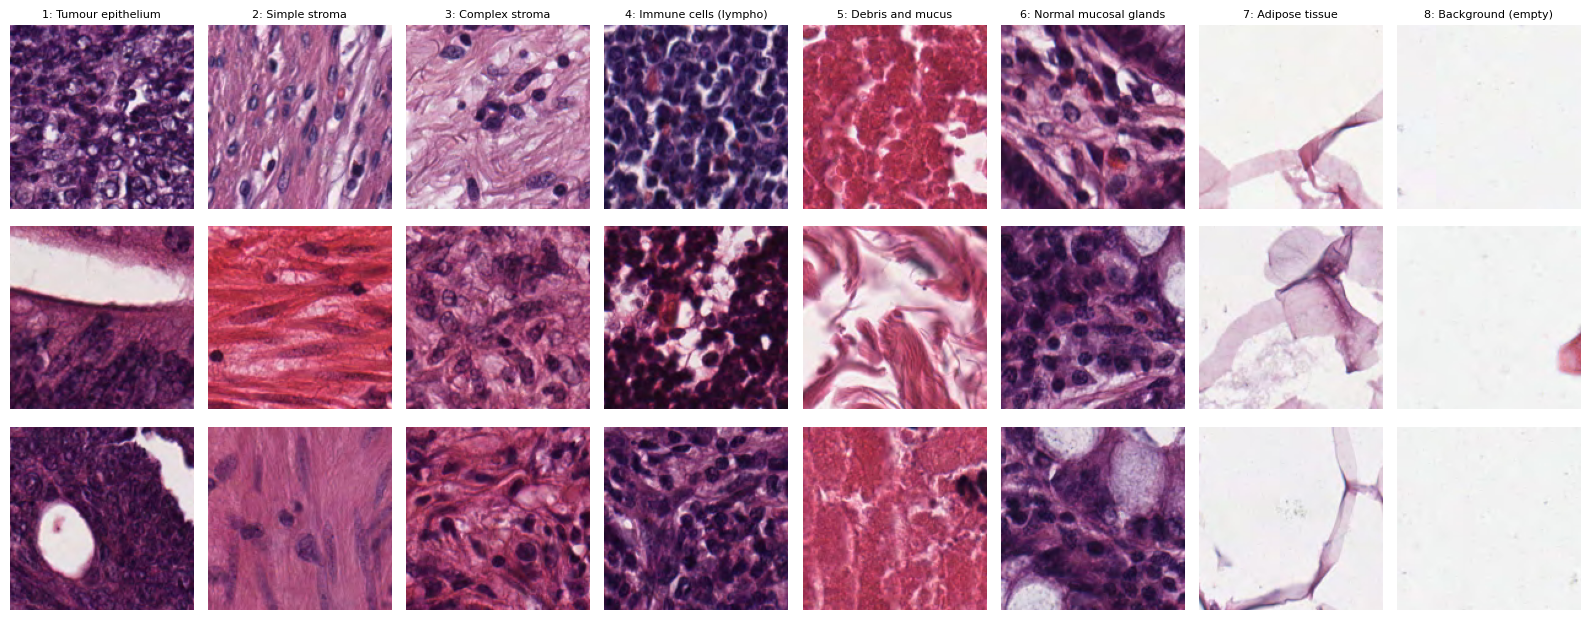

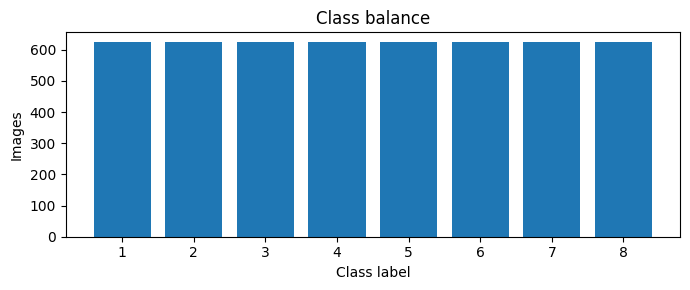

In [5]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(3, 8, figsize=(16, 6.4))
for j, lab in enumerate(range(1, 9)):
    ids = rng.choice(df.index[df.label == lab].to_numpy(), size=3, replace=False)
    for i, idx in enumerate(ids):
        axes[i, j].imshow(X[idx]); axes[i, j].axis("off")
        if i == 0:
            axes[i, j].set_title(f"{lab}: {CLASS_NAMES[lab]}", fontsize=8)
plt.tight_layout(); plt.savefig("figures/eda_samples.png", dpi=150); plt.show()

counts = df.label.value_counts().sort_index()
plt.figure(figsize=(7, 3)); plt.bar(counts.index, counts.values)
plt.xlabel("Class label"); plt.ylabel("Images"); plt.title("Class balance")
plt.tight_layout(); plt.savefig("figures/eda_class_balance.png", dpi=150); plt.show()

### 4.2 Per-class colour and texture statistics
Per image: mean/std of R, G, B; grayscale contrast (std); and gradient energy (a simple edge/texture measure). Computed in chunks to keep memory low.

                       class brightness        contrast        grad_energy  \
                                   mean    std     mean    std        mean   
label                                                                        
1          Tumour epithelium      77.58  17.05    43.30  13.58       17.85   
2              Simple stroma     122.08  23.53    35.74  12.40       18.75   
3             Complex stroma     100.28  19.31    39.06   7.08       21.44   
4      Immune cells (lympho)      73.75  19.97    45.71  10.84       23.17   
5           Debris and mucus     143.37  31.00    41.58  10.37       18.59   
6      Normal mucosal glands     110.85  19.07    51.00   5.36       20.28   
7             Adipose tissue     227.98   9.41    24.07   9.64        5.74   
8         Background (empty)     242.03   2.78     3.11   4.00        0.87   

              meanR          meanG          meanB         
        std    mean    std    mean    std    mean    std  
label                  

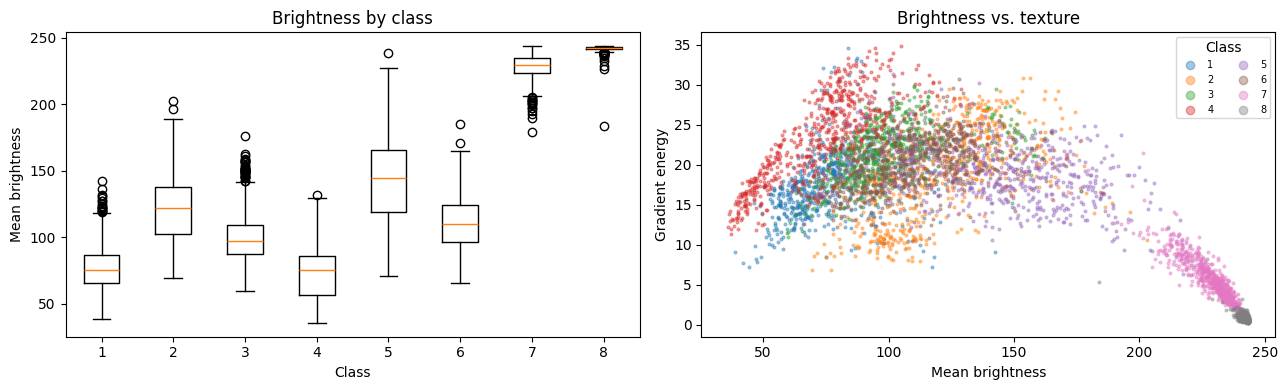

In [6]:
GRAY_W = np.array([0.299, 0.587, 0.114], dtype=np.float32)

def image_features(X, chunk=500):
    feats = []
    for s in range(0, len(X), chunk):
        xb = X[s:s + chunk].astype(np.float32)               # (b,150,150,3)
        gray = xb @ GRAY_W                                   # (b,150,150)
        grad = np.abs(np.diff(gray, axis=1)).mean(axis=(1, 2)) + np.abs(np.diff(gray, axis=2)).mean(axis=(1, 2))
        hist = np.stack([np.histogram(g, bins=16, range=(0, 255))[0] / g.size for g in gray])
        feats.append(np.column_stack([xb.mean(axis=(1, 2)), xb.std(axis=(1, 2)), grad, hist]))
    return np.vstack(feats)

F = image_features(X)
FEAT_NAMES = ["meanR", "meanG", "meanB", "stdR", "stdG", "stdB", "grad_energy"] + [f"hist{i}" for i in range(16)]
feat_df = pd.DataFrame(F, columns=FEAT_NAMES); feat_df["label"] = df.label.to_numpy()
feat_df["brightness"] = feat_df[["meanR", "meanG", "meanB"]].to_numpy() @ GRAY_W
feat_df["contrast"] = feat_df[["stdR", "stdG", "stdB"]].mean(axis=1)

class_stats = feat_df.groupby("label")[["brightness", "contrast", "grad_energy", "meanR", "meanG", "meanB"]].agg(["mean", "std"]).round(2)
class_stats.insert(0, "class", [CLASS_NAMES[l] for l in class_stats.index])
class_stats.to_csv("results/eda_class_stats.csv")
display(class_stats) if "display" in globals() else print(class_stats)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].boxplot([feat_df.brightness[feat_df.label == l] for l in range(1, 9)])
ax[0].set_xticks(range(1, 9)); ax[0].set_xticklabels(range(1, 9))
ax[0].set_xlabel("Class"); ax[0].set_ylabel("Mean brightness"); ax[0].set_title("Brightness by class")
for l in range(1, 9):
    s = feat_df[feat_df.label == l]
    ax[1].scatter(s.brightness, s.grad_energy, s=4, alpha=0.4, label=str(l))
ax[1].set_xlabel("Mean brightness"); ax[1].set_ylabel("Gradient energy"); ax[1].set_title("Brightness vs. texture")
ax[1].legend(title="Class", markerscale=3, ncol=2, fontsize=7)
plt.tight_layout(); plt.savefig("figures/eda_class_stats.png", dpi=150); plt.show()

### 4.3 Which classes are similar? (descriptive sanity check, not a model result)
A nearest-centroid classifier on the simple hand-crafted features above shows which classes are easy or hard to separate by colour/texture alone. The centroid-distance heatmap shows which class pairs are close. Both inform the discussion of the class split in Section 6.

Nearest-centroid accuracy on simple features: 0.673
1: Tumour epithelium        0.706
2: Simple stroma            0.495
3: Complex stroma           0.482
4: Immune cells (lympho)    0.569
5: Debris and mucus         0.597
6: Normal mucosal glands    0.665
7: Adipose tissue           0.875
8: Background (empty)       0.990


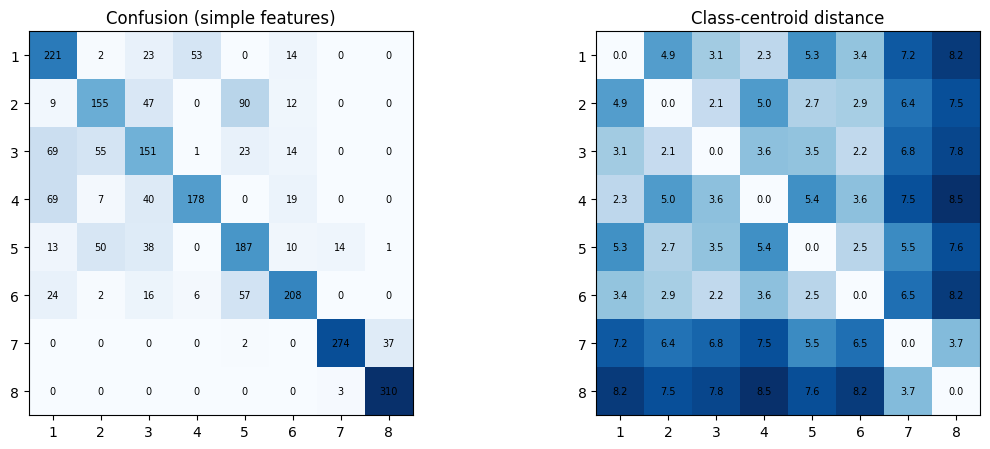

In [7]:
Fz = F.copy(); mu, sd = Fz.mean(0), Fz.std(0) + 1e-8; Fz = (Fz - mu) / sd
y = df.label.to_numpy()

# 50/50 stratified split for the sanity check
rng = np.random.default_rng(SEED)
tr = np.zeros(len(y), bool)
for l in range(1, 9):
    idx = rng.permutation(np.where(y == l)[0]); tr[idx[: len(idx) // 2]] = True
cent = np.stack([Fz[tr & (y == l)].mean(0) for l in range(1, 9)])
pred = np.argmin(((Fz[~tr, None, :] - cent[None]) ** 2).sum(-1), axis=1) + 1
acc = (pred == y[~tr]).mean()
conf = np.zeros((8, 8), int)
for t, p_ in zip(y[~tr], pred): conf[t - 1, p_ - 1] += 1
recall = conf.diagonal() / conf.sum(1)
print(f"Nearest-centroid accuracy on simple features: {acc:.3f}")
print(pd.Series(recall, index=[f"{l}: {CLASS_NAMES[l]}" for l in range(1, 9)]).round(3).to_string())

all_cent = np.stack([Fz[y == l].mean(0) for l in range(1, 9)])
dist = np.sqrt(((all_cent[:, None] - all_cent[None]) ** 2).sum(-1))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
for a, M, title, fmt in [(ax[0], conf, "Confusion (simple features)", "d"), (ax[1], dist, "Class-centroid distance", ".1f")]:
    a.imshow(M, cmap="Blues"); a.set_title(title)
    a.set_xticks(range(8)); a.set_xticklabels(range(1, 9)); a.set_yticks(range(8)); a.set_yticklabels(range(1, 9))
    for i in range(8):
        for j in range(8):
            a.text(j, i, format(M[i, j], fmt), ha="center", va="center", fontsize=7)
plt.tight_layout(); plt.savefig("figures/eda_separability.png", dpi=150); plt.show()
json.dump({"nearest_centroid_acc": float(acc), "per_class_recall": {int(l): float(r) for l, r in zip(range(1, 9), recall)}},
          open("results/eda_separability.json", "w"), indent=2)

## 5. Preprocessing and augmentation

preprocess output: (3, 224, 224) float32 | range -2.0 to 2.34


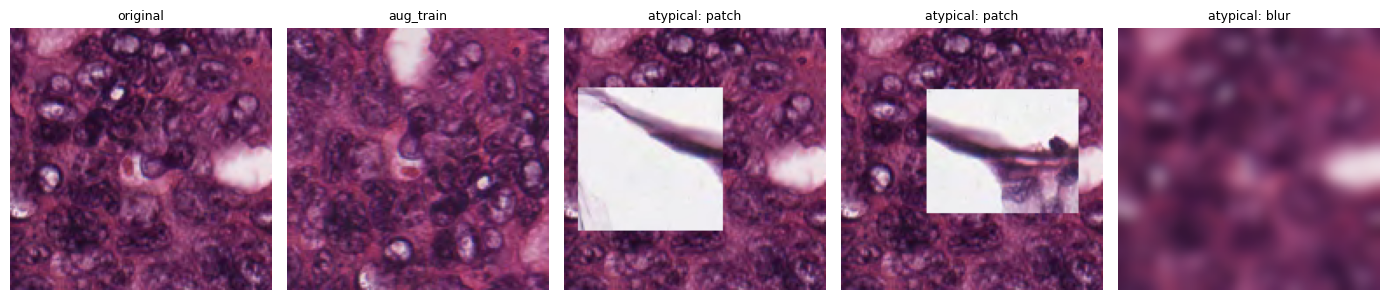

In [8]:
INPUT_SIZE = 224
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype=np.float32)
IMAGENET_STD = np.array([0.229, 0.224, 0.225], dtype=np.float32)

def preprocess(img_u8, size=INPUT_SIZE):
    im = Image.fromarray(img_u8).resize((size, size), RESAMPLE.BICUBIC)
    a = (np.asarray(im, dtype=np.float32) / 255.0 - IMAGENET_MEAN) / IMAGENET_STD
    return a.transpose(2, 0, 1)                                   # (3, H, W)

def deprocess(a):
    return np.clip((a.transpose(1, 2, 0) * IMAGENET_STD + IMAGENET_MEAN) * 255, 0, 255).astype(np.uint8)

def _jitter(im, rng, b, c, s):
    for enh, amt in ((ImageEnhance.Brightness, b), (ImageEnhance.Contrast, c), (ImageEnhance.Color, s)):
        im = enh(im).enhance(1 + rng.uniform(-amt, amt))
    return im

def aug_train(img_u8, rng):
    im = Image.fromarray(img_u8)
    if rng.random() < 0.5: im = im.transpose(TRANSPOSE.FLIP_LEFT_RIGHT)
    if rng.random() < 0.5: im = im.transpose(TRANSPOSE.FLIP_TOP_BOTTOM)
    im = im.rotate(int(rng.choice([0, 90, 180, 270])))
    return np.asarray(_jitter(im, rng, 0.2, 0.2, 0.2), dtype=np.uint8)

def make_atypical(img_u8, rng, other_u8=None):
    kinds = ["stain", "blur"] + (["patch"] if other_u8 is not None else [])
    kind = str(rng.choice(kinds))
    if kind == "stain":
        im = _jitter(Image.fromarray(img_u8), rng, 0.4, 0.4, 0.8)
        a = np.asarray(im, dtype=np.float32) * rng.uniform(0.7, 1.3, size=3)
        out = np.clip(a, 0, 255).astype(np.uint8)
    elif kind == "blur":
        out = np.asarray(Image.fromarray(img_u8).filter(ImageFilter.GaussianBlur(radius=float(rng.uniform(2, 4)))), dtype=np.uint8)
    else:
        out = img_u8.copy(); h, w = out.shape[:2]
        ph, pw = int(h * rng.uniform(0.4, 0.6)), int(w * rng.uniform(0.4, 0.6))
        y0, x0 = int(rng.integers(0, h - ph)), int(rng.integers(0, w - pw))
        out[y0:y0 + ph, x0:x0 + pw] = other_u8[y0:y0 + ph, x0:x0 + pw]
    return out, kind

# --- verify and illustrate ---
t = preprocess(X[0])
print("preprocess output:", t.shape, t.dtype, "| range", round(float(t.min()), 2), "to", round(float(t.max()), 2))
assert t.shape == (3, 224, 224) and t.dtype == np.float32
assert deprocess(t).shape == (224, 224, 3)

rng = np.random.default_rng(SEED)
i = int(df.index[df.label == 1][0]); j = int(df.index[df.label == 7][0])
variants = [("original", X[i]), ("aug_train", aug_train(X[i], rng))]
for _ in range(3):
    img, kind = make_atypical(X[i], rng, X[j]); variants.append((f"atypical: {kind}", img))
fig, axes = plt.subplots(1, 5, figsize=(14, 3))
for a, (title, img) in zip(axes, variants):
    a.imshow(img); a.set_title(title, fontsize=9); a.axis("off")
plt.tight_layout(); plt.savefig("figures/preprocessing_examples.png", dpi=150); plt.show()

## 6. Fixed class splits

In [9]:
SPLITS = {
    "A": {"base": [2, 5, 7, 8], "novel": [1, 3, 4, 6]},   # primary
    "B": {"base": [1, 4, 6, 8], "novel": [2, 3, 5, 7]},   # alternate
    "C": {"base": [3, 4, 7, 8], "novel": [1, 2, 5, 6]},   # alternate
}
for k, s in SPLITS.items():
    assert len(s["base"]) == len(s["novel"]) == 4
    assert set(s["base"]).isdisjoint(s["novel"]) and set(s["base"]) | set(s["novel"]) == set(range(1, 9)), k

VAL_FRACTION = 0.20
roles = pd.DataFrame({"id": df.index, "label": df.label.to_numpy()})
for k, s in SPLITS.items():
    r = np.array(["novel_test"] * len(df), dtype=object)
    rng = np.random.default_rng(SEED + ord(k))
    for c in s["base"]:
        ids = rng.permutation(np.where(df.label.to_numpy() == c)[0]); n_val = int(round(VAL_FRACTION * len(ids)))
        r[ids[:n_val]] = "base_val"; r[ids[n_val:]] = "base_train"
    roles[f"role_{k}"] = r

json.dump({"seed": SEED, "val_fraction": VAL_FRACTION, "splits": SPLITS}, open("splits/class_splits.json", "w"), indent=2)
roles.to_csv("splits/image_roles.csv", index=False)

rows = []
for k in SPLITS:
    for role, g in roles.groupby(f"role_{k}"):
        rows.append((k, role, sorted(g.label.unique().tolist()), len(g)))
role_summary = pd.DataFrame(rows, columns=["split", "role", "classes", "images"])
role_summary.to_csv("results/split_summary.csv", index=False)
print(role_summary.to_string(index=False))

split       role      classes  images
    A base_train [2, 5, 7, 8]    2000
    A   base_val [2, 5, 7, 8]     500
    A novel_test [1, 3, 4, 6]    2500
    B base_train [1, 4, 6, 8]    2000
    B   base_val [1, 4, 6, 8]     500
    B novel_test [2, 3, 5, 7]    2500
    C base_train [3, 4, 7, 8]    2000
    C   base_val [3, 4, 7, 8]     500
    C novel_test [1, 2, 5, 6]    2500


## 7. Seeded episode sampler


In [10]:
N_WAY, N_QUERY, K_MAX, SHOTS = 4, 15, 10, (1, 5, 10)
N_TEST_EPISODES, N_VAL_EPISODES = 600, 300
TEST_SEED0, VAL_SEED0 = 10_000, 20_000

def ids_by_class(role_series, label_series, role, classes):
    mask = (role_series.to_numpy() == role)
    return {c: np.sort(np.where(mask & (label_series.to_numpy() == c))[0]) for c in classes}

def sample_episode(pool, classes, n_way, k_shot, n_query, rng, query_offset):
    # pool: {class: array of image ids}. Support = first k_shot of a shuffled list,
    # query = n_query images starting at query_offset (>= k_shot) so they never overlap.
    assert query_offset >= k_shot
    chosen = [int(c) for c in rng.choice(classes, size=n_way, replace=False)]
    support, query = [], []
    for c in chosen:
        perm = rng.permutation(pool[c])
        assert len(perm) >= query_offset + n_query, f"class {c} has too few images"
        support.append([int(i) for i in perm[:k_shot]])
        query.append([int(i) for i in perm[query_offset:query_offset + n_query]])
    return {"classes": chosen, "support": support, "query": query}

def build_fixed_episodes(pool, classes, n_episodes, seed0):
    out = {str(k): [] for k in SHOTS}
    for i in range(n_episodes):
        for k in SHOTS:
            ep = sample_episode(pool, classes, N_WAY, k, N_QUERY, np.random.default_rng(seed0 + i), K_MAX)
            ep["seed"] = seed0 + i; out[str(k)].append(ep)
    return out

def sample_train_episode(pool, classes, k_shot, rng, n_way=N_WAY, n_query=N_QUERY):
    return sample_episode(pool, classes, n_way, k_shot, n_query, rng, query_offset=k_shot)

def episode_arrays(ep, X):
    # Returns support (n_way*k, H, W, 3), support labels, query (n_way*q, H, W, 3), query labels (labels are 0..n_way-1).
    sx = np.stack([X[i] for cls in ep["support"] for i in cls]); sy = np.repeat(np.arange(len(ep["support"])), len(ep["support"][0]))
    qx = np.stack([X[i] for cls in ep["query"] for i in cls]);   qy = np.repeat(np.arange(len(ep["query"])), len(ep["query"][0]))
    return sx, sy, qx, qy

episodes = {}
for k, s in SPLITS.items():
    pool_test = ids_by_class(roles[f"role_{k}"], roles.label, "novel_test", s["novel"])
    pool_val = ids_by_class(roles[f"role_{k}"], roles.label, "base_val", s["base"])
    # base_val has ~125 images/class: enough for 10 + 15 = 25 per class
    episodes[k] = {"test": build_fixed_episodes(pool_test, s["novel"], N_TEST_EPISODES, TEST_SEED0),
                   "val": build_fixed_episodes(pool_val, s["base"], N_VAL_EPISODES, VAL_SEED0)}
    json.dump(episodes[k]["test"], open(f"splits/test_episodes_{k}.json", "w"))
    json.dump(episodes[k]["val"], open(f"splits/val_episodes_{k}.json", "w"))
print("Saved fixed episodes for splits:", list(episodes))

Saved fixed episodes for splits: ['A', 'B', 'C']


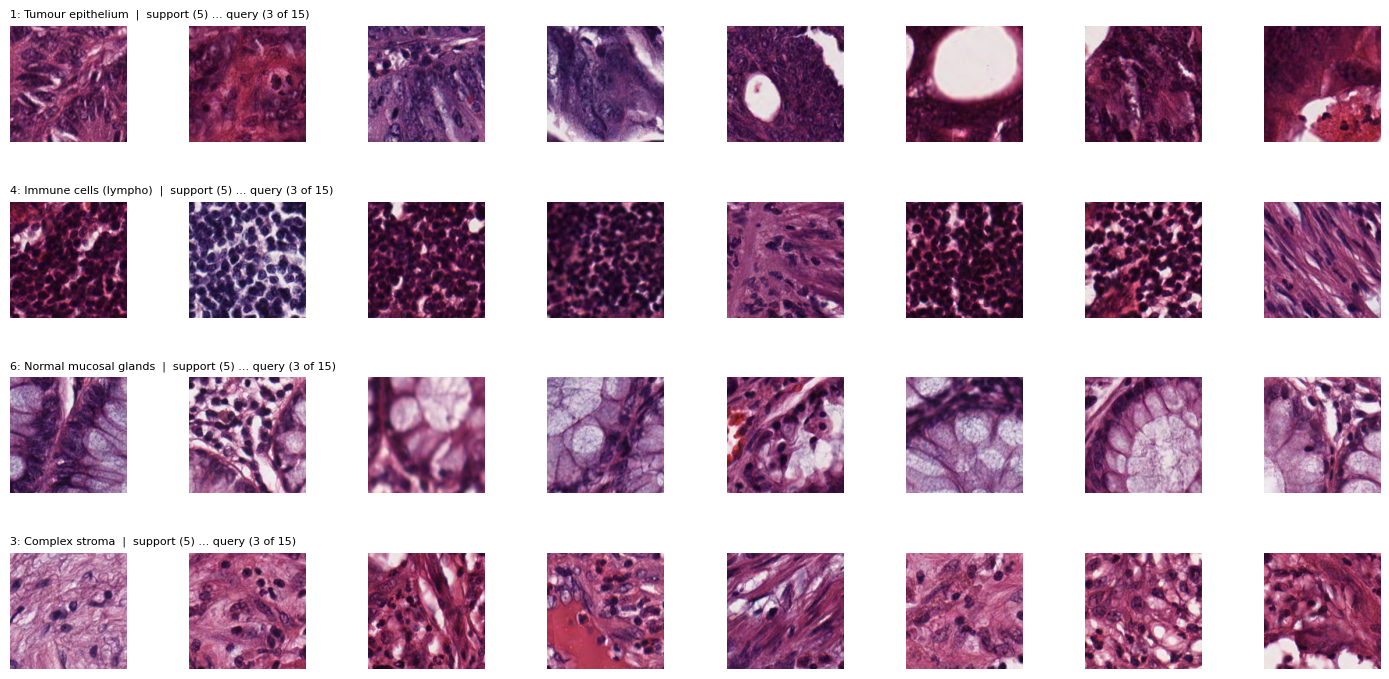

In [11]:
# Illustration: one 4-way 5-shot test episode (split A)
ep = episodes["A"]["test"]["5"][0]
sx, sy, qx, qy = episode_arrays(ep, X)
fig, axes = plt.subplots(4, 8, figsize=(14, 7.2))
for r, c in enumerate(ep["classes"]):
    for j in range(5):
        axes[r, j].imshow(sx[r * 5 + j]); axes[r, j].axis("off")
    for j in range(3):
        axes[r, 5 + j].imshow(qx[r * N_QUERY + j]); axes[r, 5 + j].axis("off")
    axes[r, 0].set_title(f"{c}: {CLASS_NAMES[c]}  |  support (5) ... query (3 of 15)", fontsize=8, loc="left")
plt.tight_layout(); plt.savefig("figures/episode_example.png", dpi=150); plt.show()

## 8. Verification and summary


In [12]:
checks = {}

# 1. Fixed episodes: structure, class/role membership, disjointness, nesting, shared queries
ok_struct = ok_roles = ok_disjoint = ok_nested = ok_queries = True
for k, s in SPLITS.items():
    role = roles[f"role_{k}"].to_numpy(); lab = roles.label.to_numpy()
    for part, expected_role, expected_classes, n_ep in [("test", "novel_test", s["novel"], N_TEST_EPISODES), ("val", "base_val", s["base"], N_VAL_EPISODES)]:
        for kk in SHOTS:
            eps = episodes[k][part][str(kk)]
            ok_struct &= len(eps) == n_ep
            for ep in eps:
                ok_struct &= len(ep["classes"]) == N_WAY and set(ep["classes"]) <= set(expected_classes)
                for ci, c in enumerate(ep["classes"]):
                    sup, qry = ep["support"][ci], ep["query"][ci]
                    ok_struct &= len(sup) == kk and len(qry) == N_QUERY
                    ok_disjoint &= set(sup).isdisjoint(qry) and len(set(sup)) == len(sup) and len(set(qry)) == len(qry)
                    ok_roles &= bool(np.all(role[sup + qry] == expected_role)) and bool(np.all(lab[sup + qry] == c))
        e1, e5, e10 = (episodes[k][part][str(kk)] for kk in SHOTS)
        for a, b_, c_ in zip(e1, e5, e10):
            ok_queries &= a["query"] == b_["query"] == c_["query"] and a["classes"] == b_["classes"] == c_["classes"]
            ok_nested &= all(set(x1) <= set(x5) <= set(x10) for x1, x5, x10 in zip(a["support"], b_["support"], c_["support"]))
checks["episode structure (sizes, classes)"] = bool(ok_struct)
checks["episode images match role and label"] = bool(ok_roles)
checks["support/query disjoint within each episode"] = bool(ok_disjoint)
checks["supports nested across 1/5/10-shot"] = bool(ok_nested)
checks["queries & class sets shared across shots"] = bool(ok_queries)

# 2. Reproducibility: rebuilding with the same seeds gives identical episodes
s = SPLITS["A"]; pool = ids_by_class(roles["role_A"], roles.label, "novel_test", s["novel"])
rebuilt = build_fixed_episodes(pool, s["novel"], 20, TEST_SEED0)
checks["episodes reproducible from seeds"] = all(rebuilt[str(k)] == episodes["A"]["test"][str(k)][:20] for k in SHOTS)

# 3. No leakage: base_train never overlaps test/val; novel classes never in base roles
leak = True
for k, s in SPLITS.items():
    r = roles[f"role_{k}"]
    leak &= set(roles.label[r == "novel_test"]) == set(s["novel"]) and set(roles.label[r != "novel_test"]) == set(s["base"])
checks["novel-class images never in base roles"] = bool(leak)

# 4. A sampled training episode comes only from base_train
rngt = np.random.default_rng(0); sA = SPLITS["A"]
pool_tr = ids_by_class(roles["role_A"], roles.label, "base_train", sA["base"])
tep = sample_train_episode(pool_tr, sA["base"], 5, rngt)
ids_ = [i for cl in tep["support"] + tep["query"] for i in cl]
checks["training episode uses base_train only"] = bool(np.all(roles["role_A"].to_numpy()[ids_] == "base_train"))

# 5. Data checks
checks["5,000 images after cleaning (or fewer only if duplicates/corrupt removed)"] = report["n_clean"] == 5000 - report["corrupt_files"] - report["exact_duplicates_removed"]
checks["all images 150x150 RGB uint8"] = X.shape[1:] == (150, 150, 3) and X.dtype == np.uint8
checks["8 labels (1-8)"] = report["labels_after_cleaning"] == list(range(1, 9))

for name, ok in checks.items():
    print(("PASS  " if ok else "FAIL  ") + name)
assert all(checks.values()), "One or more checks failed"

PASS  episode structure (sizes, classes)
PASS  episode images match role and label
PASS  support/query disjoint within each episode
PASS  supports nested across 1/5/10-shot
PASS  queries & class sets shared across shots
PASS  episodes reproducible from seeds
PASS  novel-class images never in base roles
PASS  training episode uses base_train only
PASS  5,000 images after cleaning (or fewer only if duplicates/corrupt removed)
PASS  all images 150x150 RGB uint8
PASS  8 labels (1-8)


In [13]:
summary = {
    "dataset": "Colorectal Histology MNIST (Kaggle kmader/colorectal-histology-mnist), from Kather et al. 2016",
    "files_used": "150x150 RGB tile folders (CSV versions not used)",
    "n_images_clean": report["n_clean"], "n_classes": 8, "per_class_counts": report["per_class_counts"],
    "corrupt_removed": report["corrupt_files"], "duplicates_removed": report["exact_duplicates_removed"],
    "missing_values": report["missing_values"], "stored_format": "uint8 RGB 150x150",
    "model_input": "224x224 float32, ImageNet-normalised (applied on the fly)",
    "protocol": f"in-domain, {N_WAY}-way, shots {list(SHOTS)}, {N_QUERY} queries/class",
    "splits": SPLITS, "test_episodes_per_shot": N_TEST_EPISODES, "val_episodes_per_shot": N_VAL_EPISODES,
    "test_seed_base": TEST_SEED0, "val_seed_base": VAL_SEED0, "global_seed": SEED,
    "checks_passed": {k: bool(v) for k, v in checks.items()},
}
json.dump(summary, open("results/phase2_summary.json", "w"), indent=2)
print(json.dumps(summary, indent=2))

with open("requirements.txt", "w") as f:
    f.write("numpy\npandas\npillow\nmatplotlib\nkagglehub\n")
print("\nFiles written: data/processed/index_clean.csv, splits/*, results/*, figures/*, requirements.txt")

{
  "dataset": "Colorectal Histology MNIST (Kaggle kmader/colorectal-histology-mnist), from Kather et al. 2016",
  "files_used": "150x150 RGB tile folders (CSV versions not used)",
  "n_images_clean": 5000,
  "n_classes": 8,
  "per_class_counts": {
    "1": 625,
    "2": 625,
    "3": 625,
    "4": 625,
    "5": 625,
    "6": 625,
    "7": 625,
    "8": 625
  },
  "corrupt_removed": 0,
  "duplicates_removed": 0,
  "missing_values": 0,
  "stored_format": "uint8 RGB 150x150",
  "model_input": "224x224 float32, ImageNet-normalised (applied on the fly)",
  "protocol": "in-domain, 4-way, shots [1, 5, 10], 15 queries/class",
  "splits": {
    "A": {
      "base": [
        2,
        5,
        7,
        8
      ],
      "novel": [
        1,
        3,
        4,
        6
      ]
    },
    "B": {
      "base": [
        1,
        4,
        6,
        8
      ],
      "novel": [
        2,
        3,
        5,
        7
      ]
    },
    "C": {
      "base": [
        3,
        4,
  

**Citations:** Kather, J. N. et al. (2016). Multi-class texture analysis in colorectal cancer histology. *Scientific Reports*, 6, 27988. Kaggle mirror: kmader/colorectal-histology-mnist.